In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os


# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [2]:
from pathlib import Path
import pandas as pd

# 1. Define your root dataset directory
# Update this to your actual Kaggle input path
ROOT_DIR = Path("/kaggle/input/datasets/alieldinalaa/nn-cmp27-dataset") 

data_records = []

print("Scanning directories...")
# rglob("*.wav") recursively hunts down every audio file in the tree
for wav_path in ROOT_DIR.rglob("*.wav"):
    
    # Extract metadata based on your specific folder structure
    label = wav_path.parent.name                  # e.g., 'Abnormal' or 'Normal'
    machine_name = wav_path.parent.parent.parent.name # e.g., 'Machine 1'
    
    try:
        # wav_path.stem gets the filename without the '.wav' extension
        file_num = int(wav_path.stem)             
    except ValueError:
        continue # Skip any hidden files or weirdly named files
        
    data_records.append({
        'file_path': str(wav_path),
        'machine_name': machine_name,
        'label': label,
        'file_num': file_num
    })

# Create the foundational DataFrame and sort it strictly chronologically
full_df = pd.DataFrame(data_records)
full_df = full_df.sort_values(by=['machine_name', 'label', 'file_num']).reset_index(drop=True)

print(f"Successfully loaded {len(full_df)} files into the DataFrame.")
full_df.head()

Scanning directories...
Successfully loaded 56236 files into the DataFrame.


,file_path,machine_name,label,file_num
0,/kaggle/input/datasets/alieldinalaa/nn-cmp27-d...,Machine 1,Abnormal,1
1,/kaggle/input/datasets/alieldinalaa/nn-cmp27-d...,Machine 1,Abnormal,2
2,/kaggle/input/datasets/alieldinalaa/nn-cmp27-d...,Machine 1,Abnormal,3
3,/kaggle/input/datasets/alieldinalaa/nn-cmp27-d...,Machine 1,Abnormal,4
4,/kaggle/input/datasets/alieldinalaa/nn-cmp27-d...,Machine 1,Abnormal,5


In [3]:
from sklearn.model_selection import train_test_split

# =========================================================
# STEP 1: Isolate the Test Set (15% of the total data)
# =========================================================
train_val_df, test_df = train_test_split(
    full_df,
    test_size=0.15,
    random_state=42,
    stratify=full_df['label']  # Locks in the exact Normal/Abnormal ratio
)

# =========================================================
# STEP 2: Isolate the Validation Set (~15% of the total data)
# =========================================================
# To make Val equal to 15% of the original 56,000 files, we calculate:
# 0.15 / 0.85 = 0.17647 (We take ~17.6% of the remaining train_val block)
train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.17647,
    random_state=42,
    stratify=train_val_df['label']  # Maintains the ratio again
)

# =========================================================
# STEP 3: Clean up and Verify
# =========================================================
# Reset indices so the dataframes are clean for XGBoost extraction
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("✅ Standard Stratified 3-Way Split Successful!")
print("=" * 45)
print(f"Total files:      {len(full_df)}")
print(f"Training Set:     {len(train_df)} files ({len(train_df)/len(full_df)*100:.1f}%)")
print(f"Validation Set:   {len(val_df)} files ({len(val_df)/len(full_df)*100:.1f}%)")
print(f"Test Set:         {len(test_df)} files ({len(test_df)/len(full_df)*100:.1f}%)")
print("=" * 45)

# Verify the stratification ratio is identical across all splits
print("\n🔍 Stratification Check (Abnormal vs Normal Ratio):")
print("Train Set Ratio:\n", train_df['label'].value_counts(normalize=True).round(3))
print("\nValidation Set Ratio:\n", val_df['label'].value_counts(normalize=True).round(3))

✅ Standard Stratified 3-Way Split Successful!
Total files:      56236
Training Set:     39364 files (70.0%)
Validation Set:   8436 files (15.0%)
Test Set:         8436 files (15.0%)

🔍 Stratification Check (Abnormal vs Normal Ratio):
Train Set Ratio:
 label
Normal      0.832
Abnormal    0.168
Name: proportion, dtype: float64

Validation Set Ratio:
 label
Normal      0.832
Abnormal    0.168
Name: proportion, dtype: float64


In [4]:
import librosa
import numpy as np

def extract_basic_features(file_path):
    """
    Extracts RMS Energy and Zero Crossing Rate from an audio file,
    and returns their Mean, Std, Max, and Min.
    """
    try:
        # Load the audio file (sr=None preserves the original sampling rate)
        y, sr = librosa.load(file_path, sr=None)
        
        # 1. Extract the raw features over time (returns 2D arrays)
        # RMS Energy measures the physical loudness
        rms = librosa.feature.rms(y=y)
        
        # ZCR measures the harshness/noisiness
        zcr = librosa.feature.zero_crossing_rate(y=y)
        
        # 2. Calculate the Statistical Summaries
        features = {
            'rms_mean': np.mean(rms),
            'rms_std': np.std(rms),
            'rms_max': np.max(rms),
            'rms_min': np.min(rms),
            
            'zcr_mean': np.mean(zcr),
            'zcr_std': np.std(zcr),
            'zcr_max': np.max(zcr),
            'zcr_min': np.min(zcr)
        }
        
        return features
        
    except Exception as e:
        # Fallback for corrupted files to prevent the loop from crashing
        print(f"Error processing {file_path}: {e}")
        return {
            'rms_mean': 0.0, 'rms_std': 0.0, 'rms_max': 0.0, 'rms_min': 0.0,
            'zcr_mean': 0.0, 'zcr_std': 0.0, 'zcr_max': 0.0, 'zcr_min': 0.0
        }

# --- Quick Test ---
test_path = train_df['file_path'].iloc[0]
print(extract_basic_features(test_path))

{'rms_mean': np.float32(0.00051232317), 'rms_std': np.float32(0.00082945987), 'rms_max': np.float32(0.008677437), 'rms_min': np.float32(5.8138947e-05), 'zcr_mean': np.float64(0.19035351183987403), 'zcr_std': np.float64(0.11233676791142355), 'zcr_max': np.float64(0.48876953125), 'zcr_min': np.float64(0.0791015625)}


In [5]:
import os
import librosa
import numpy as np
import pandas as pd
from tqdm import tqdm
from joblib import Parallel, delayed

# =========================================================
# 1. The 64-Feature Extractor
# =========================================================
def extract_all_features(file_path):
    """
    Extracts RMS, ZCR, Spectral Centroid, and 13 MFCCs.
    Calculates Mean, Std, Max, and Min for all of them.
    Returns a flat dictionary of 64 features.
    """
    features = {}
    try:
        y, sr = librosa.load(file_path, sr=None)
        
        # --- 1. Extract Raw 2D Audio Sequences ---
        rms = librosa.feature.rms(y=y)[0]
        zcr = librosa.feature.zero_crossing_rate(y=y)[0]
        centroid = librosa.feature.spectral_centroid(y=y, sr=sr)[0]
        mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13) # Shape: (13, time_steps)
        
        # --- 2. Define a Helper for Statistical Expansion ---
        def add_stats(name, array):
            features[f'{name}_mean'] = np.mean(array)
            features[f'{name}_std'] = np.std(array)
            features[f'{name}_max'] = np.max(array)
            features[f'{name}_min'] = np.min(array)
            
        # --- 3. Calculate and Store Stats ---
        add_stats('rms', rms)
        add_stats('zcr', zcr)
        add_stats('centroid', centroid)
        
        for i in range(13):
            add_stats(f'mfcc_{i+1}', mfccs[i])
            
        return features
        
    except Exception as e:
        # If a file is corrupted, return an empty dict (Pandas will fill with NaNs, which we handle later)
        return {}

# =========================================================
# 2. The Parallel Processing Wrapper
# =========================================================
def process_dataframe(df, split_name):
    print(f"\nProcessing {split_name} Set ({len(df)} files)...")
    
    # Run the extraction in parallel across all CPU cores
    extracted_list = Parallel(n_jobs=-1)(
        delayed(extract_all_features)(row['file_path']) 
        for _, row in tqdm(df.iterrows(), total=len(df), desc=f"{split_name} Features")
    )
    
    # Convert the list of dictionaries into a new DataFrame
    features_df = pd.DataFrame(extracted_list)
    
    # Fill any missing values (from corrupted files) with 0
    features_df = features_df.fillna(0)
    
    # Concatenate the new feature columns directly next to the original data (file_path, label, etc.)
    final_df = pd.concat([df.reset_index(drop=True), features_df.reset_index(drop=True)], axis=1)
    return final_df

# =========================================================
# 3. Execute and Export
# =========================================================
# Run the processor on all three splits
train_final = process_dataframe(train_df, "Training")
val_final = process_dataframe(val_df, "Validation")
test_final = process_dataframe(test_df, "Test")

# Define the Kaggle working directory for saving
output_dir = '/kaggle/working/'
os.makedirs(output_dir, exist_ok=True)

# Save to CSV
train_final.to_csv(os.path.join(output_dir, 'cmp27_train_tabular.csv'), index=False)
val_final.to_csv(os.path.join(output_dir, 'cmp27_val_tabular.csv'), index=False)
test_final.to_csv(os.path.join(output_dir, 'cmp27_test_tabular.csv'), index=False)

print("\n" + "="*50)
print("✅ EXTRACTION COMPLETE AND DATA SECURED.")
print(f"Features Generated per file: {train_final.shape[1] - len(train_df.columns)}")
print(f"Files saved to {output_dir}")
print("="*50)


Processing Training Set (39364 files)...


Training Features: 100%|██████████| 39364/39364 [29:01<00:00, 22.61it/s]



Processing Validation Set (8436 files)...


Validation Features: 100%|██████████| 8436/8436 [06:06<00:00, 22.99it/s]



Processing Test Set (8436 files)...


Test Features: 100%|██████████| 8436/8436 [06:13<00:00, 22.56it/s]



✅ EXTRACTION COMPLETE AND DATA SECURED.
Features Generated per file: 64
Files saved to /kaggle/working/


# XGBoost

In [6]:
import pandas as pd

def prepare_multi_class_data(df):
    """
    Fuses the machine name and label into a single 6-class target,
    maps it to integers 0-5, and isolates the feature matrix.
    """
    # 1. Create a temporary fused string column (e.g., 'Machine 1_Normal')
    df['fused_target'] = df['machine_name'] + '_' + df['label']
    
    # 2. Define the exact integer mapping
    class_map = {
        'Machine 1_Normal': 0,
        'Machine 1_Abnormal': 1,
        'Machine 2_Normal': 2,
        'Machine 2_Abnormal': 3,
        'Machine 3_Normal': 4,
        'Machine 3_Abnormal': 5
    }
    
    # 3. Extract the Target (y)
    y = df['fused_target'].map(class_map)
    
    # 4. Extract the Features (X) by dropping all metadata
    # We drop the original strings, our temporary fused column, and the structural IDs
    columns_to_drop = ['file_path', 'machine_name', 'label', 'fused_target']
    
    # Safely drop file_num and session_id if they exist in this dataframe
    for col in ['file_num', 'session_id']:
        if col in df.columns:
            columns_to_drop.append(col)
            
    X = df.drop(columns=columns_to_drop)
    
    return X, y

# Execute the preparation on all three splits
X_train, y_train = prepare_multi_class_data(train_final)
X_val, y_val = prepare_multi_class_data(val_final)
X_test, y_test = prepare_multi_class_data(test_final)

print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print("Target classes mapped successfully: 0 through 5.")

X_train shape: (39364, 64) | y_train shape: (39364,)
Target classes mapped successfully: 0 through 5.


In [8]:
from sklearn.model_selection import ParameterGrid
from xgboost import XGBClassifier

# 1. Define the Hyperparameter Grid to explore
param_grid = {
    'max_depth': [3, 5, 7],               
    'learning_rate': [0.01, 0.05, 0.1],   
    'n_estimators': [500, 1000]           
}

grid = ParameterGrid(param_grid)

best_logloss = float('inf')
best_params = None
best_model = None

print(f"Starting Grid Search: {len(grid)} combinations to test.\n")

# 2. The Tuning Loop
for i, params in enumerate(grid):
    print(f"Testing combination {i+1}/{len(grid)}: {params}")
    
    # Initialize the engine (Early stopping moved HERE)
    model = XGBClassifier(
        **params,
        objective='multi:softprob', 
        num_class=6,
        random_state=42,
        n_jobs=-1,
        early_stopping_rounds=50
    )
    
    # Train the model
    model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        verbose=False             
    )
    
    # Retrieve the best Log Loss achieved
    val_loss = model.best_score
    
    if val_loss < best_logloss:
        best_logloss = val_loss
        best_params = params
        best_model = model

print("-" * 50)
print(f"✅ Tuning Complete. Best Validation Log Loss: {best_logloss:.4f}")
print(f"🏆 Champion Parameters: {best_params}")

Starting Grid Search: 18 combinations to test.

Testing combination 1/18: {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 500}
Testing combination 2/18: {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 1000}
Testing combination 3/18: {'learning_rate': 0.01, 'max_depth': 5, 'n_estimators': 500}
Testing combination 4/18: {'learning_rate': 0.01, 'max_depth': 5, 'n_estimators': 1000}
Testing combination 5/18: {'learning_rate': 0.01, 'max_depth': 7, 'n_estimators': 500}
Testing combination 6/18: {'learning_rate': 0.01, 'max_depth': 7, 'n_estimators': 1000}
Testing combination 7/18: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 500}
Testing combination 8/18: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 1000}
Testing combination 9/18: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 500}
Testing combination 10/18: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 1000}
Testing combination 11/18: {'learning_rate': 0.05, 'max_depth': 7, 'n_estima

Deploying Champion Model on Unseen Test Data...

CLASSIFICATION REPORT (TEST SET)
                    precision    recall  f1-score   support

  Machine 1 Normal       1.00      1.00      1.00      2425
Machine 1 Abnormal       0.99      0.99      0.99       469
  Machine 2 Normal       1.00      1.00      1.00      2449
Machine 2 Abnormal       1.00      0.99      1.00       489
  Machine 3 Normal       1.00      1.00      1.00      2146
Machine 3 Abnormal       1.00      1.00      1.00       458

          accuracy                           1.00      8436
         macro avg       1.00      1.00      1.00      8436
      weighted avg       1.00      1.00      1.00      8436



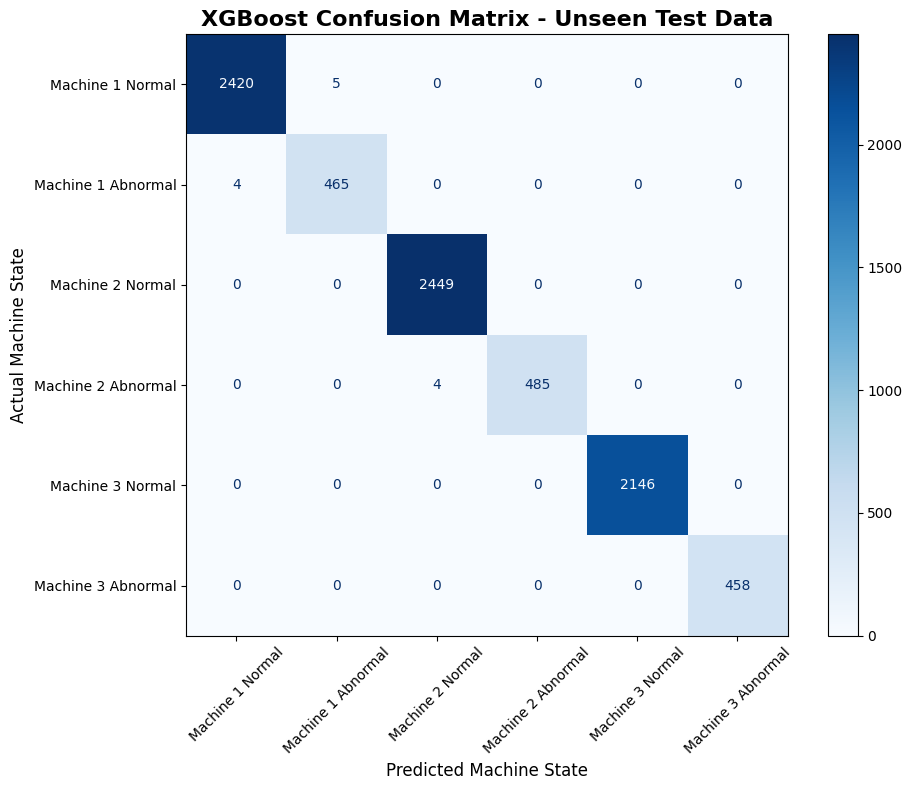

In [21]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

print("Deploying Champion Model on Unseen Test Data...")

# 1. Generate predictions on the Test set
y_pred = best_model.predict(X_test)

# Define the exact names of the 6 classes to make the outputs readable
target_names = [
    'Machine 1 Normal', 'Machine 1 Abnormal', 
    'Machine 2 Normal', 'Machine 2 Abnormal', 
    'Machine 3 Normal', 'Machine 3 Abnormal'
]

# =========================================================
# 2. Print Precision, Recall, and F1-Score
# =========================================================
print("\n" + "="*60)
print("CLASSIFICATION REPORT (TEST SET)")
print("="*60)
# classification_report automatically calculates everything you asked for
print(classification_report(y_test, y_pred, target_names=target_names))

# =========================================================
# 3. Plot the Confusion Matrix Image
# =========================================================
fig, ax = plt.subplots(figsize=(10, 8))

# ConfusionMatrixDisplay is the cleanest way to plot this in modern sklearn
disp = ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred, 
    display_labels=target_names,
    cmap=plt.cm.Blues,      # A clean blue color gradient
    xticks_rotation=45,     # Tilt the x-labels so they don't overlap
    ax=ax
)

plt.title("XGBoost Confusion Matrix - Unseen Test Data", fontsize=16, fontweight='bold')
plt.xlabel("Predicted Machine State", fontsize=12)
plt.ylabel("Actual Machine State", fontsize=12)

# Adjust layout to ensure the tilted labels fit on the screen
plt.tight_layout()
plt.show()

In [23]:
import os

output_dir = '/kaggle/working/'
os.makedirs(output_dir, exist_ok=True)

# Save XGBoost natively as a JSON file
xgb_path = os.path.join(output_dir, 'champion_xgboost_multi_class.json')

# Assuming your best model from the grid search is stored in `best_xgb_model`
best_model.save_model(xgb_path)

print(f"✅ XGBoost model securely saved to: {xgb_path}")

✅ XGBoost model securely saved to: /kaggle/working/champion_xgboost_multi_class.json


# SVM

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print("Phase 1: Feature Scaling...")
# 1. Initialize the Scaler
scaler = StandardScaler()

# 2. Fit strictly on Training, then transform all three
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

Phase 1: Feature Scaling...


In [11]:
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Phase 2: SVM Hyperparameter Tuning...")
# 3. Define a conservative SVM grid (SVMs are slow to train!)
# C = Regularization (penalty for misclassification)
# gamma = Kernel coefficient (how far the influence of a single sample reaches)
param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['rbf', 'linear'],
    'gamma': ['scale'] # 'scale' is a highly optimized default for RBF
}

grid = ParameterGrid(param_grid)

best_f1 = -1.0 # For SVM, we tune directly to the Macro F1-Score
best_params = None
best_model = None

for i, params in enumerate(grid):
    print(f"Testing combination {i+1}/{len(grid)}: {params}")
    
    # Initialize the SVM Engine
    # probability=False makes training much faster if you don't need exact % confidences
    model = SVC(
        **params,
        decision_function_shape='ovo', # One-vs-One is standard for multi-class SVM
        random_state=42
    )
    
    # Train the model (No early stopping in standard SVM)
    model.fit(X_train_scaled, y_train)
    
    # Evaluate on the Validation set
    y_val_pred = model.predict(X_val_scaled)
    val_f1 = f1_score(y_val, y_val_pred, average='macro')
    
    print(f"  -> Validation Macro F1: {val_f1:.4f}")
    
    if val_f1 > best_f1:
        best_f1 = val_f1
        best_params = params
        best_model = model

print("-" * 50)
print(f"✅ Tuning Complete. Best Validation F1: {best_f1:.4f}")
print(f"🏆 Champion Parameters: {best_params}")

Phase 2: SVM Hyperparameter Tuning...
Testing combination 1/6: {'C': 0.1, 'gamma': 'scale', 'kernel': 'rbf'}
  -> Validation Macro F1: 0.9484
Testing combination 2/6: {'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}
  -> Validation Macro F1: 0.9611
Testing combination 3/6: {'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}
  -> Validation Macro F1: 0.9847
Testing combination 4/6: {'C': 1, 'gamma': 'scale', 'kernel': 'linear'}
  -> Validation Macro F1: 0.9670
Testing combination 5/6: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
  -> Validation Macro F1: 0.9973
Testing combination 6/6: {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}
  -> Validation Macro F1: 0.9703
--------------------------------------------------
✅ Tuning Complete. Best Validation F1: 0.9973
🏆 Champion Parameters: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}



Deploying Champion SVM on Unseen Test Data...

CLASSIFICATION REPORT (SVM TEST SET)
                    precision    recall  f1-score   support

  Machine 1 Normal       1.00      1.00      1.00      2425
Machine 1 Abnormal       0.98      0.98      0.98       469
  Machine 2 Normal       1.00      1.00      1.00      2449
Machine 2 Abnormal       1.00      0.98      0.99       489
  Machine 3 Normal       1.00      1.00      1.00      2146
Machine 3 Abnormal       1.00      1.00      1.00       458

          accuracy                           1.00      8436
         macro avg       1.00      0.99      0.99      8436
      weighted avg       1.00      1.00      1.00      8436



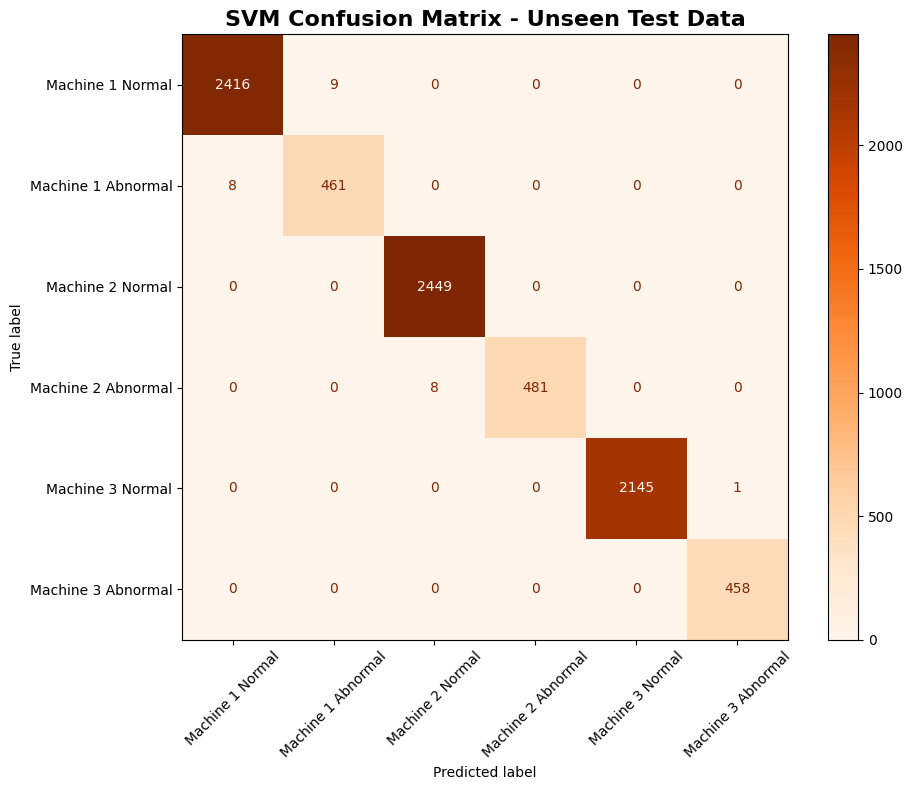

In [12]:
print("\nDeploying Champion SVM on Unseen Test Data...")
y_pred = best_model.predict(X_test_scaled)

target_names = [
    'Machine 1 Normal', 'Machine 1 Abnormal', 
    'Machine 2 Normal', 'Machine 2 Abnormal', 
    'Machine 3 Normal', 'Machine 3 Abnormal'
]

print("\n" + "="*60)
print("CLASSIFICATION REPORT (SVM TEST SET)")
print("="*60)
print(classification_report(y_test, y_pred, target_names=target_names))

# Plot the Confusion Matrix
fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred, 
    display_labels=target_names,
    cmap=plt.cm.Oranges, # Swapped to Orange to visually distinguish from XGBoost
    xticks_rotation=45,
    ax=ax
)

plt.title("SVM Confusion Matrix - Unseen Test Data", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [13]:
import joblib

# Define the paths
svm_path = os.path.join(output_dir, 'champion_svm_model.joblib')
scaler_path = os.path.join(output_dir, 'svm_feature_scaler.joblib')

# Dump both the model AND the scaler to disk
joblib.dump(best_model, svm_path)
joblib.dump(scaler, scaler_path)

print(f"✅ SVM model securely saved to: {svm_path}")
print(f"✅ SVM Scaler securely saved to: {scaler_path}")

✅ SVM model securely saved to: /kaggle/working/champion_svm_model.joblib
✅ SVM Scaler securely saved to: /kaggle/working/svm_feature_scaler.joblib
